In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the clustering dataset made in prepared_dataset.ipynb
cl = pd.read_csv("prepared_clustering.csv")

# These 4 columns are labels, not inputs: we use them later to understand the clusters
labels = ["id", "neighbourhood_group_cleansed", "license_status", "short_stay"]
X = cl.drop(columns=labels)
print(X.shape)

(19396, 17)


   k  inertia  silhouette
0  3   171629       0.235
1  4   155996       0.192
2  5   143949       0.157
3  6   134263       0.171
4  7   126659       0.170
5  8   121835       0.164


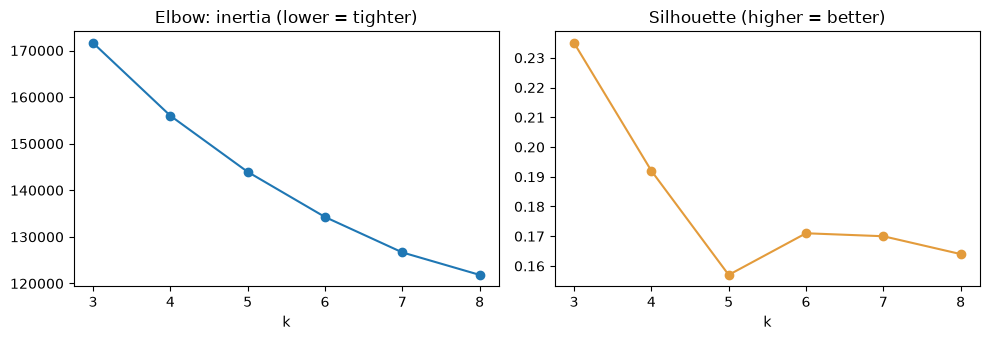

In [7]:
# Clustering 1: try k = 3 to 8 and score each
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []
for k in range(3, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    sil = silhouette_score(X, km.labels_, sample_size=5000, random_state=42)
    results.append((k, round(km.inertia_), round(sil, 3)))
results = pd.DataFrame(results, columns=["k", "inertia", "silhouette"])
print(results)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(results["k"], results["inertia"], marker="o"); ax[0].set_title("Elbow: inertia (lower = tighter)"); ax[0].set_xlabel("k")
ax[1].plot(results["k"], results["silhouette"], marker="o", color="#E39B3B"); ax[1].set_title("Silhouette (higher = better)"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.savefig("mining_choose_k.png"); plt.show()

In [8]:
# Clustering 2: final k = 6, then describe each cluster using real (unscaled) values
km = KMeans(n_clusters=6, n_init=10, random_state=42).fit(X)
cl["cluster"] = km.labels_

clean = pd.read_csv("listings_clean.csv")
prof = cl[["id", "cluster", "neighbourhood_group_cleansed", "license_status", "short_stay"]].merge(
    clean[["id", "price", "room_type", "property_type", "accommodates", "minimum_nights",
           "availability_365", "number_of_reviews", "calculated_host_listings_count"]], on="id")
prof["is_hotel"] = prof["property_type"].str.contains("hotel", case=False, na=False)

profile = prof.groupby("cluster").agg(
    listings=("id", "count"),
    median_price=("price", "median"),
    pct_entire_home=("room_type", lambda s: (s == "Entire home/apt").mean() * 100),
    pct_hotel=("is_hotel", lambda s: s.mean() * 100),
    pct_short_stay=("short_stay", lambda s: s.mean() * 100),
    median_min_nights=("minimum_nights", "median"),
    median_availability=("availability_365", "median"),
    median_reviews=("number_of_reviews", "median"),
    median_host_listings=("calculated_host_listings_count", "median"),
    pct_manhattan=("neighbourhood_group_cleansed", lambda s: (s == "Manhattan").mean() * 100),
).round(1)
profile

,listings,median_price,pct_entire_home,pct_hotel,pct_short_stay,median_min_nights,median_availability,median_reviews,median_host_listings,pct_manhattan
cluster,,,,,,,,,,
0,5334,134.5,64.2,0.1,0.9,30.0,251.0,24.0,1.0,29.7
1,3142,269.0,31.7,15.6,99.6,1.0,242.5,90.0,2.0,39.1
2,4747,95.9,31.1,1.3,0.9,30.0,333.0,0.0,2.0,30.4
3,1775,414.8,89.4,4.6,21.0,30.0,300.0,4.0,2.0,41.2
4,1772,616.5,17.4,68.8,85.9,1.0,307.0,1.0,8.0,80.4
5,2626,212.4,88.1,0.4,0.8,30.0,277.0,1.0,151.0,88.9


license_status,exempt,none,registered
cluster_name,,,
Big-operator apartments,0.9,99.1,0.0
"Cheap rooms, never reviewed",0.5,98.7,0.9
Hotel rooms,57.3,37.5,5.2
"Monthly homes, small hosts",0.3,98.5,1.2
Popular short stays,35.5,7.3,57.2
Pricey whole homes,15.8,78.8,5.4


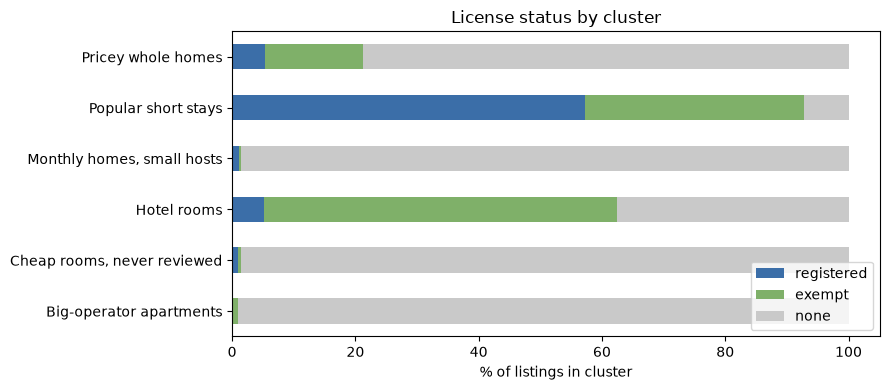

In [9]:
# Clustering 3: name the clusters and compare license status in each
names = {0: "Monthly homes, small hosts", 1: "Popular short stays", 2: "Cheap rooms, never reviewed",
         3: "Pricey whole homes", 4: "Hotel rooms", 5: "Big-operator apartments"}
prof["cluster_name"] = prof["cluster"].map(names)

lic = pd.crosstab(prof["cluster_name"], prof["license_status"], normalize="index").mul(100).round(1)
display(lic)

lic[["registered", "exempt", "none"]].plot(kind="barh", stacked=True, figsize=(9, 4),
                                           color=["#3B6EA8", "#7FB069", "#C9C9C9"])
plt.xlabel("% of listings in cluster"); plt.ylabel("")
plt.title("License status by cluster")
plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig("mining_cluster_license.png"); plt.show()

In [10]:
# Association rules 0: install the library (only needed once)
!pip install mlxtend

In [11]:
# Association rules 1: find item combinations that appear together
from mlxtend.frequent_patterns import apriori, association_rules

items = pd.read_csv("prepared_transactions.csv").astype(bool)
print(items.shape)

# itemsets found in at least 5% of listings, up to 3 items each
freq = apriori(items, min_support=0.05, use_colnames=True, max_len=3)
try:
    rules = association_rules(freq, metric="confidence", min_threshold=0.6)
except TypeError:
    rules = association_rules(freq, num_itemsets=len(items), metric="confidence", min_threshold=0.6)
print("Frequent itemsets:", len(freq), "| Rules:", len(rules))

# Keep rules that predict something about the law, hotels or big hosts
focus = ["short_stay", "license_registered", "license_exempt", "hotel", "professional_host"]
rules["if"] = rules["antecedents"].apply(lambda s: " + ".join(sorted(s)))
rules["then"] = rules["consequents"].apply(lambda s: " + ".join(sorted(s)))
key = rules[rules["then"].isin(focus)].sort_values("lift", ascending=False)
key[["if", "then", "support", "confidence", "lift"]].round(3).head(15)

(29918, 60)
Frequent itemsets: 20819 | Rules: 36754


,if,then,support,confidence,lift
9254,amen_free_street_parking + short_stay,license_registered,0.052,0.744,9.982
9240,amen_cooking_basics + short_stay,license_registered,0.054,0.609,8.168
2147,boro_Manhattan + short_stay,license_exempt,0.077,0.725,7.538
6565,amen_dedicated_workspace + license_exempt,short_stay,0.064,0.993,5.149
6556,amen_bed_linens + license_exempt,short_stay,0.078,0.992,5.142
6571,amen_self_check-in + license_exempt,short_stay,0.065,0.992,5.142
6574,amen_coffee_maker + license_exempt,short_stay,0.051,0.991,5.140
6532,amen_carbon_monoxide_alarm + license_exempt,short_stay,0.085,0.989,5.126
6568,amen_fire_extinguisher + license_exempt,short_stay,0.065,0.989,5.126
6558,amen_refrigerator + license_exempt,short_stay,0.055,0.988,5.125


In [12]:
# Save the key rules for the report
key[["if", "then", "support", "confidence", "lift"]].round(3).to_csv("mining_rules.csv", index=False)

# Anomaly detection 1: Isolation Forest flags the 2% most unusual listings
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=200, contamination=0.02, random_state=42).fit(X)
cl["anomaly_score"] = -iso.score_samples(X)      # higher = more unusual
cl["is_anomaly"] = iso.predict(X) == -1

prof = prof.merge(cl[["id", "anomaly_score", "is_anomaly"]], on="id")
print("Anomalies flagged:", prof["is_anomaly"].sum())

# Where do the anomalies fall?
print("\n% of each cluster flagged as anomaly:")
print(prof.groupby("cluster_name")["is_anomaly"].mean().mul(100).round(1).sort_values(ascending=False))

nolic = prof["short_stay"] & (prof["license_status"] == "none")
print("\nAnomaly rate, all priced listings:", round(prof["is_anomaly"].mean() * 100, 1), "%")
print("Anomaly rate, short stays with no license:", round(prof.loc[nolic, "is_anomaly"].mean() * 100, 1), "%")

Anomalies flagged: 388

% of each cluster flagged as anomaly:
cluster_name
Pricey whole homes             15.4
Hotel rooms                     5.2
Popular short stays             0.5
Cheap rooms, never reviewed     0.1
Big-operator apartments         0.0
Monthly homes, small hosts      0.0
Name: is_anomaly, dtype: float64

Anomaly rate, all priced listings: 2.0 %
Anomaly rate, short stays with no license: 0.0 %


,listings,median_price,median_guests,median_min_nights,median_reviews,median_host_listings,pct_short_stay
Normal,19008,179.0,2.0,30.0,7.0,3.0,25.5
Anomaly,388,1125.7,8.0,1.0,1.5,10.0,73.2


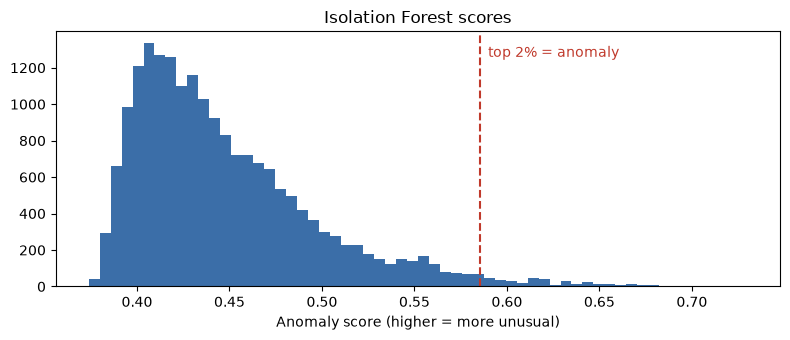

,cluster_name,room_type,neighbourhood_group_cleansed,accommodates,price,minimum_nights,number_of_reviews
10597,Pricey whole homes,Shared room,Manhattan,14,3325.00,1.0,108
19199,Pricey whole homes,Private room,Manhattan,16,5742.94,30.0,0
14816,Pricey whole homes,Entire home/apt,Manhattan,16,4563.00,1.0,2
11631,Pricey whole homes,Entire home/apt,Brooklyn,16,4161.33,3.0,1
11713,Pricey whole homes,Entire home/apt,Brooklyn,16,6360.00,3.0,0


In [13]:
# Anomaly detection 2: how do anomalies differ from normal listings?
compare = prof.groupby("is_anomaly").agg(
    listings=("id", "count"),
    median_price=("price", "median"),
    median_guests=("accommodates", "median"),
    median_min_nights=("minimum_nights", "median"),
    median_reviews=("number_of_reviews", "median"),
    median_host_listings=("calculated_host_listings_count", "median"),
    pct_short_stay=("short_stay", lambda s: s.mean() * 100),
).round(1)
compare.index = ["Normal", "Anomaly"]
display(compare)

# Score distribution with the cutoff marked
cut = prof.loc[prof["is_anomaly"], "anomaly_score"].min()
plt.figure(figsize=(8, 3.5))
plt.hist(prof["anomaly_score"], bins=60, color="#3B6EA8")
plt.axvline(cut, color="#C0392B", linestyle="--")
plt.text(cut, plt.ylim()[1] * 0.9, "  top 2% = anomaly", color="#C0392B")
plt.xlabel("Anomaly score (higher = more unusual)"); plt.title("Isolation Forest scores")
plt.tight_layout(); plt.savefig("mining_anomaly_scores.png"); plt.show()

# 5 most unusual listings
prof.sort_values("anomaly_score", ascending=False)[
    ["cluster_name", "room_type", "neighbourhood_group_cleansed", "accommodates", "price", "minimum_nights", "number_of_reviews"]].head(5)